# Session 1: Introduction to Statistics

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    pass  # numpy, pandas, scipy, statsmodels and matplotlib are preinstalled in Colab
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/03-inferential-statistical-analysis/code/'
    for f in []:
        if not os.path.exists(f):
            subprocess.run(['wget', '-q', base + f], check=False)
print('ready')

ready


## Example: `session-01_data_types.py`

In [2]:
"""
Session 1 · Example 1: Types of data and frequency tables
---------------------------------------------------------
Before computing any statistic you must know WHAT KIND of variable you have.
This script builds a small survey of 12 students, labels every column with its
level of measurement, and prints the summaries that are valid for each level.

Run:  python session-01_data_types.py
"""
import pandas as pd

# A tiny survey from a Karachi classroom (made-up but realistic values).
survey = pd.DataFrame({
    "student":      ["Ali", "Sara", "Bilal", "Hira", "Usman", "Zoya",
                     "Hamza", "Iqra", "Saad", "Maha", "Fahad", "Noor"],
    "area":         ["Gulshan", "Clifton", "Gulshan", "DHA", "Saddar", "Clifton",
                     "Gulshan", "DHA", "Saddar", "Gulshan", "Clifton", "DHA"],
    "grade":        ["B", "A", "C", "A", "B", "A", "C", "B", "B", "A", "C", "B"],
    "temp_c":       [31, 29, 33, 30, 34, 28, 32, 30, 35, 31, 29, 30],      # room temperature at home
    "siblings":     [2, 1, 3, 0, 4, 1, 2, 2, 5, 1, 3, 0],
    "commute_min":  [35, 20, 40, 15, 55, 25, 30, 18, 60, 33, 22, 16],
})

# Level of measurement for each variable, and what you are allowed to do with it.
levels = {
    "area":        ("Nominal",  "categories, no order -> counts, mode"),
    "grade":       ("Ordinal",  "ordered categories -> counts, mode, median"),
    "temp_c":      ("Interval", "equal steps, no true zero -> mean, std (no ratios)"),
    "siblings":    ("Ratio (discrete)",   "true zero, counts -> every statistic"),
    "commute_min": ("Ratio (continuous)", "true zero, measured -> every statistic"),
}
print("Variable      Level                Valid summaries")
print("-" * 72)
for col, (lvl, ok) in levels.items():
    print(f"{col:<13} {lvl:<20} {ok}")

# 1) Nominal: a frequency table with relative and percentage frequency
freq = survey["area"].value_counts().rename("count").to_frame()
freq["relative"] = (freq["count"] / freq["count"].sum()).round(3)
freq["percent"] = (freq["relative"] * 100).round(1)
print("\nFrequency table for 'area' (nominal):")
print(freq.to_string())
print("Mode of area:", survey["area"].mode().tolist())

# 2) Ordinal: keep the natural order A > B > C, then the median makes sense
grade_order = pd.CategoricalDtype(["C", "B", "A"], ordered=True)
grades = survey["grade"].astype(grade_order)
counts = grades.value_counts(sort=False)
print("\nGrade counts in order (ordinal):", {k: int(v) for k, v in counts.items()})
median_code = int(grades.cat.codes.median())          # codes: C=0, B=1, A=2
print("Median grade:", grade_order.categories[median_code])

# 3) Interval vs ratio: 35 C is NOT "1.25x as hot" as 28 C (0 C is not "no heat"),
#    but a 60-minute commute IS 4x a 15-minute one (0 minutes really means none).
print(f"\nCommute ratio Saad/Hira = {survey.commute_min[8] / survey.commute_min[3]:.1f}x (valid: ratio scale)")

# 4) Grouped frequency table (class intervals) for a continuous variable
bins = [10, 20, 30, 40, 50, 60]
classes = pd.cut(survey["commute_min"], bins=bins, right=True)
grouped = classes.value_counts(sort=False).rename("students").to_frame()
grouped["cumulative"] = grouped["students"].cumsum()
print("\nGrouped frequency table for commute (minutes):")
print(grouped.to_string())

Variable      Level                Valid summaries
------------------------------------------------------------------------
area          Nominal              categories, no order -> counts, mode
grade         Ordinal              ordered categories -> counts, mode, median
temp_c        Interval             equal steps, no true zero -> mean, std (no ratios)
siblings      Ratio (discrete)     true zero, counts -> every statistic
commute_min   Ratio (continuous)   true zero, measured -> every statistic

Frequency table for 'area' (nominal):
         count  relative  percent
area                             
Gulshan      4     0.333     33.3
Clifton      3     0.250     25.0
DHA          3     0.250     25.0
Saddar       2     0.167     16.7
Mode of area: ['Gulshan']

Grade counts in order (ordinal): {'C': 3, 'B': 5, 'A': 4}
Median grade: B

Commute ratio Saad/Hira = 4.0x (valid: ratio scale)

Grouped frequency table for commute (minutes):
             students  cumulative
commute_min    

## Example: `session-01_central_tendency.py`

In [3]:
"""
Session 1 · Example 2: Mean, median, mode and the effect of an outlier
----------------------------------------------------------------------
We compute every measure of central tendency TWICE: once by hand with plain
Python (so you see the formula) and once with the library (so you trust it).
Then one CEO salary is added to show why the median is 'robust'.

Run:  python session-01_central_tendency.py
"""
from collections import Counter
import statistics as st
import numpy as np

# Monthly salaries (thousand PKR) of 9 employees at a small software house
salaries = [85, 90, 95, 95, 110, 120, 130, 140, 160]

def mean(xs):
    """Arithmetic mean: sum of values divided by how many there are."""
    return sum(xs) / len(xs)

def median(xs):
    """Middle value of the SORTED data (average of the two middles if n is even)."""
    s = sorted(xs)
    n = len(s)
    mid = n // 2
    return s[mid] if n % 2 == 1 else (s[mid - 1] + s[mid]) / 2

def modes(xs):
    """All values that occur most often (data can be multimodal)."""
    c = Counter(xs)
    top = max(c.values())
    return [v for v, k in c.items() if k == top]

print("Salaries (k PKR):", salaries)
print(f"By hand  -> mean {mean(salaries):.2f}, median {median(salaries)}, mode {modes(salaries)}")
print(f"Library  -> mean {np.mean(salaries):.2f}, median {np.median(salaries)}, mode {st.multimode(salaries)}")

# Weighted mean: a student's GPA where courses carry different credit hours
grades_points = [4.0, 3.3, 3.7, 2.7]
credit_hours = [3, 4, 3, 1]
gpa = sum(g * w for g, w in zip(grades_points, credit_hours)) / sum(credit_hours)
print(f"\nWeighted mean (GPA) = {gpa:.3f}   (np.average gives {np.average(grades_points, weights=credit_hours):.3f})")

# Geometric mean: the right average for growth rates
growth = [1.10, 1.25, 0.95]          # +10 %, +25 %, -5 % yearly growth of a shop's revenue
gm = st.geometric_mean(growth)
print(f"Geometric mean growth factor = {gm:.4f} -> average growth {100 * (gm - 1):.2f}% per year")
print(f"(The arithmetic mean would wrongly say {100 * (mean(growth) - 1):.2f}% per year)")

# Harmonic mean: the right average for rates such as speed over equal distances
speeds = [60, 40]                      # km/h there and back on the same road
print(f"Harmonic mean speed = {st.harmonic_mean(speeds):.1f} km/h (not {mean(speeds):.0f})")

# The outlier test: the owner adds her own salary
with_ceo = salaries + [1500]
print("\nAdd one owner salary of 1500k:")
print(f"  mean   {mean(salaries):7.2f} -> {mean(with_ceo):7.2f}   (jumps by {mean(with_ceo) - mean(salaries):.1f})")
print(f"  median {median(salaries):7.2f} -> {median(with_ceo):7.2f}   (moves by {median(with_ceo) - median(salaries):.1f})")
print(f"  trimmed mean (drop top & bottom 10%): {st.mean(sorted(with_ceo)[1:-1]):.2f}")
print("Conclusion: report the MEDIAN for skewed data such as salaries or house prices.")

Salaries (k PKR): [85, 90, 95, 95, 110, 120, 130, 140, 160]
By hand  -> mean 113.89, median 110, mode [95]
Library  -> mean 113.89, median 110.0, mode [95]

Weighted mean (GPA) = 3.545   (np.average gives 3.545)
Geometric mean growth factor = 1.0931 -> average growth 9.31% per year
(The arithmetic mean would wrongly say 10.00% per year)
Harmonic mean speed = 48.0 km/h (not 50)

Add one owner salary of 1500k:
  mean    113.89 ->  252.50   (jumps by 138.6)
  median  110.00 ->  115.00   (moves by 5.0)
  trimmed mean (drop top & bottom 10%): 117.50
Conclusion: report the MEDIAN for skewed data such as salaries or house prices.


## Example: `session-01_dispersion_shape.py`

In [4]:
"""
Session 1 · Example 3: Spread and shape, with a chart
-----------------------------------------------------
Two food-delivery riders have the SAME average delivery time but very different
reliability. Measures of dispersion (range, variance, standard deviation, IQR,
coefficient of variation) and shape (skewness, kurtosis) reveal the difference.
The script also saves a histogram + box plot: session-01_dispersion_shape.png

Run:  python session-01_dispersion_shape.py
"""
import numpy as np
import matplotlib
matplotlib.use("Agg")                      # draw to a file, no window needed
import matplotlib.pyplot as plt
from scipy import stats

# Delivery times in minutes for 15 orders each (deterministic data, no randomness)
rider_a = np.array([28, 29, 30, 30, 31, 29, 30, 31, 30, 32, 29, 30, 31, 30, 30])
rider_b = np.array([15, 18, 45, 20, 50, 22, 25, 40, 19, 38, 21, 55, 24, 23, 35])

def summary(name, x):
    q1, q3 = np.percentile(x, [25, 75])
    var_pop = np.var(x)              # divide by n      (population)
    var_smp = np.var(x, ddof=1)      # divide by n - 1  (sample, Bessel's correction)
    sd = np.std(x, ddof=1)
    print(f"{name}: n={len(x)}  mean={x.mean():.2f}  median={np.median(x):.1f}")
    print(f"   range={x.max() - x.min()}  IQR={q3 - q1:.1f}  (Q1={q1:.1f}, Q3={q3:.1f})")
    print(f"   variance pop={var_pop:.2f}  sample={var_smp:.2f}  std(sample)={sd:.2f}")
    print(f"   coefficient of variation = {100 * sd / x.mean():.1f}%")
    print(f"   skewness={stats.skew(x):.3f}  excess kurtosis={stats.kurtosis(x):.3f}")
    print(f"   five-number summary: {x.min()}, {q1:.1f}, {np.median(x):.1f}, {q3:.1f}, {x.max()}")

summary("Rider A", rider_a)
summary("Rider B", rider_b)

# Variance by hand for Rider A, step by step
dev = rider_a - rider_a.mean()
print("\nRider A by hand: sum of squared deviations =", round(float((dev ** 2).sum()), 2),
      "-> / (n-1) =", round(float((dev ** 2).sum() / (len(rider_a) - 1)), 3))

# Empirical rule check on Rider B (how many orders within 1 standard deviation?)
m, s = rider_b.mean(), rider_b.std(ddof=1)
inside = ((rider_b >= m - s) & (rider_b <= m + s)).sum()
print(f"Rider B: {inside}/{len(rider_b)} orders lie within mean +/- 1 sd "
      f"({m - s:.1f} to {m + s:.1f} min)")

# ---- Chart: histogram and box plot side by side --------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
bins = np.arange(10, 61, 5)
ax1.hist(rider_a, bins=bins, alpha=0.75, color="#FF6B1A", label="Rider A", edgecolor="white")
ax1.hist(rider_b, bins=bins, alpha=0.6, color="#A78BFA", label="Rider B", edgecolor="white")
ax1.axvline(rider_a.mean(), color="#0A0716", linestyle="--", linewidth=1, label="both means = 30")
ax1.set_title("Same mean, different spread")
ax1.set_xlabel("delivery time (minutes)"); ax1.set_ylabel("orders"); ax1.legend()
ax2.boxplot([rider_a, rider_b], patch_artist=True,
            boxprops=dict(facecolor="#FCD34D"), medianprops=dict(color="#F43F5E", linewidth=2))
ax2.set_xticks([1, 2]); ax2.set_xticklabels(["Rider A", "Rider B"])
ax2.set_title("Box plots: IQR and whiskers"); ax2.set_ylabel("minutes")
fig.tight_layout()
fig.savefig("session-01_dispersion_shape.png", dpi=110)
print("\nSaved chart: session-01_dispersion_shape.png")

Rider A: n=15  mean=30.00  median=30.0
   range=4  IQR=1.0  (Q1=29.5, Q3=30.5)
   variance pop=0.93  sample=1.00  std(sample)=1.00
   coefficient of variation = 3.3%
   skewness=0.000  excess kurtosis=-0.092
   five-number summary: 28, 29.5, 30.0, 30.5, 32
Rider B: n=15  mean=30.00  median=24.0
   range=40  IQR=18.5  (Q1=20.5, Q3=39.0)
   variance pop=152.27  sample=163.14  std(sample)=12.77
   coefficient of variation = 42.6%
   skewness=0.684  excess kurtosis=-0.910
   five-number summary: 15, 20.5, 24.0, 39.0, 55

Rider A by hand: sum of squared deviations = 14.0 -> / (n-1) = 1.0
Rider B: 11/15 orders lie within mean +/- 1 sd (17.2 to 42.8 min)

Saved chart: session-01_dispersion_shape.png


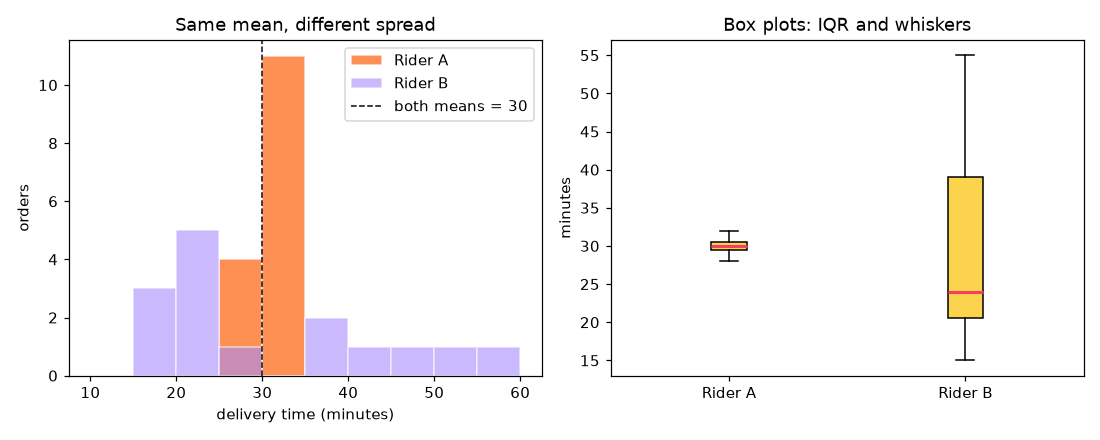

In [5]:
from IPython.display import Image, display
display(Image(filename='session-01_dispersion_shape.png'))  # chart saved by the cell above

## Example: `session-01_problem_exam_report.py`

In [6]:
"""
Session 1 · Real-life problem: the exam-result report
-----------------------------------------------------
PROBLEM
A lecturer has the final marks (out of 100) of two sections. The head of
department wants, for each section:
  1. n, mean, median, standard deviation, min, max, Q1, Q3, IQR
  2. any outliers by the 1.5 x IQR rule AND by |z| > 2.5
  3. the grade distribution (A >= 85, B >= 70, C >= 55, D >= 40, F below)
  4. a one-line verdict: which section did better and which was more consistent?

SOLUTION (pure pandas + numpy, no hidden helpers)
Run:  python session-01_problem_exam_report.py
"""
import numpy as np
import pandas as pd

marks = {
    "Section A": [72, 65, 88, 91, 54, 77, 69, 83, 95, 60, 74, 81, 12, 70, 79, 86, 68, 73],
    "Section B": [66, 71, 69, 74, 70, 68, 72, 75, 67, 73, 70, 69, 71, 76, 65, 72, 70, 74],
}

def grade(m):
    """Convert a mark to a letter grade using the department's cut-offs."""
    for cut, letter in [(85, "A"), (70, "B"), (55, "C"), (40, "D")]:
        if m >= cut:
            return letter
    return "F"

def describe_section(name, values):
    x = pd.Series(values, name=name)
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # Tukey fences
    z = (x - x.mean()) / x.std(ddof=1)                 # standard scores
    report = {
        "n": len(x), "mean": x.mean(), "median": x.median(), "std": x.std(ddof=1),
        "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(), "IQR": iqr,
        "IQR outliers": x[(x < lo) | (x > hi)].tolist(),
        "z outliers": x[z.abs() > 2.5].tolist(),
    }
    grades = x.map(grade).value_counts().reindex(list("ABCDF"), fill_value=0)
    return report, grades

rows, grade_tables = {}, {}
for name, vals in marks.items():
    rows[name], grade_tables[name] = describe_section(name, vals)

table = pd.DataFrame(rows)
pd.set_option("display.width", 100)
print("Descriptive report")
print(table.to_string(formatters=None))
print("\nGrade distribution")
print(pd.DataFrame(grade_tables).T.to_string())

# Same summary after removing the outlier from Section A (was it a data-entry error or an absent student?)
clean_a = [m for m in marks["Section A"] if m not in rows["Section A"]["IQR outliers"]]
print(f"\nSection A without outliers: mean {np.mean(clean_a):.2f}, "
      f"median {np.median(clean_a):.1f}, std {np.std(clean_a, ddof=1):.2f}")

better = max(rows, key=lambda k: rows[k]["median"])
steadier = min(rows, key=lambda k: rows[k]["IQR"])
print(f"\nVerdict: {better} has the higher median mark; {steadier} is the more consistent section "
      f"(smaller IQR). Check the outlier in Section A before publishing.")

Descriptive report
              Section A  Section B
n                    18         18
mean          72.055556  70.666667
median             73.5       70.5
std           18.421446    3.06786
min                  12         65
Q1                68.25       69.0
Q3                 82.5      72.75
max                  95         76
IQR               14.25       3.75
IQR outliers       [12]         []
z outliers         [12]         []

Grade distribution
           A   B  C  D  F
Section A  4   8  4  1  1
Section B  0  12  6  0  0

Section A without outliers: mean 75.59, median 74.0, std 11.04

Verdict: Section A has the higher median mark; Section B is the more consistent section (smaller IQR). Check the outlier in Section A before publishing.


## Example: `session-01_project_stats_toolkit.py`

In [7]:
"""
Session 1 · Mini project: build your own describe()
---------------------------------------------------
Goal: write a small, reusable descriptive-statistics toolkit WITHOUT numpy,
then prove it is correct by comparing it with pandas on a real-looking data set
(daily electricity units used by a Karachi household over 30 days).

Features
  * mean, median, mode(s), variance and std (sample or population)
  * quantiles with linear interpolation (same method as pandas/numpy default)
  * IQR, outliers, skewness (adjusted Fisher-Pearson, same as pandas)
  * a text histogram so you can 'see' the data in a terminal

Run:  python session-01_project_stats_toolkit.py
"""
from collections import Counter
import math
import pandas as pd


class Describe:
    def __init__(self, data):
        if not data:
            raise ValueError("data must not be empty")
        self.x = sorted(float(v) for v in data)
        self.n = len(self.x)

    # ---- centre --------------------------------------------------------------
    def mean(self):
        return sum(self.x) / self.n

    def median(self):
        return self.quantile(0.5)

    def modes(self):
        c = Counter(self.x)
        top = max(c.values())
        return sorted(v for v, k in c.items() if k == top) if top > 1 else []

    # ---- spread --------------------------------------------------------------
    def var(self, sample=True):
        m = self.mean()
        ss = sum((v - m) ** 2 for v in self.x)
        return ss / (self.n - 1 if sample else self.n)

    def std(self, sample=True):
        return math.sqrt(self.var(sample))

    def quantile(self, q):
        """Linear interpolation between closest ranks: position = q * (n - 1)."""
        pos = q * (self.n - 1)
        lo = math.floor(pos)
        hi = min(lo + 1, self.n - 1)
        return self.x[lo] + (pos - lo) * (self.x[hi] - self.x[lo])

    def iqr(self):
        return self.quantile(0.75) - self.quantile(0.25)

    def outliers(self, k=1.5):
        q1, q3 = self.quantile(0.25), self.quantile(0.75)
        return [v for v in self.x if v < q1 - k * self.iqr() or v > q3 + k * self.iqr()]

    # ---- shape ---------------------------------------------------------------
    def skew(self):
        """Adjusted Fisher-Pearson skewness (the formula pandas uses)."""
        m, s, n = self.mean(), self.std(), self.n
        g = sum(((v - m) / s) ** 3 for v in self.x)
        return n / ((n - 1) * (n - 2)) * g

    # ---- report --------------------------------------------------------------
    def report(self):
        return {"count": self.n, "mean": self.mean(), "std": self.std(), "min": self.x[0],
                "25%": self.quantile(0.25), "50%": self.median(), "75%": self.quantile(0.75),
                "max": self.x[-1], "skew": self.skew()}

    def text_histogram(self, bins=6, width=30):
        lo, hi = self.x[0], self.x[-1]
        step = (hi - lo) / bins
        counts = [0] * bins
        for v in self.x:
            i = min(int((v - lo) / step), bins - 1)
            counts[i] += 1
        top = max(counts)
        for i, c in enumerate(counts):
            left = lo + i * step
            print(f"  {left:6.1f}-{left + step:6.1f} | {'#' * round(width * c / top):<{width}} {c}")


units = [14, 15, 13, 16, 18, 17, 15, 14, 19, 22, 21, 16, 15, 14, 13,
         17, 18, 16, 15, 14, 31, 16, 15, 17, 18, 19, 16, 15, 14, 16]   # day 21: a wedding at home!

d = Describe(units)
mine = d.report()
theirs = pd.Series(units, dtype=float).describe().to_dict()
theirs["skew"] = pd.Series(units).skew()

print(f"{'statistic':<8} {'toolkit':>10} {'pandas':>10}  match")
for k in mine:
    ok = math.isclose(mine[k], theirs[k], rel_tol=1e-9)
    print(f"{k:<8} {mine[k]:>10.3f} {theirs[k]:>10.3f}  {'yes' if ok else 'NO'}")
print("modes:", d.modes(), "  IQR:", d.iqr(), "  outliers:", d.outliers())
print("\nText histogram of daily units:")
d.text_histogram()

statistic    toolkit     pandas  match
count        30.000     30.000  yes
mean         16.633     16.633  yes
std           3.479      3.479  yes
min          13.000     13.000  yes
25%          15.000     15.000  yes
50%          16.000     16.000  yes
75%          17.750     17.750  yes
max          31.000     31.000  yes
skew          2.652      2.652  yes
modes: [15.0, 16.0]   IQR: 2.75   outliers: [22.0, 31.0]

Text histogram of daily units:
    13.0-  16.0 | ############################## 13
    16.0-  19.0 | ############################   12
    19.0-  22.0 | #######                        3
    22.0-  25.0 | ##                             1
    25.0-  28.0 |                                0
    28.0-  31.0 | ##                             1
